# **Visión por Computadora 1 - Trabajo Práctico 2**

LUCIANA SIMON \
LUIS PAREDES \
BERNARDO EPPENSTEIN

**Objetivo:**

Implementar un detector de máximo enfoque sobre un video aplicando técnicas de análisis espectral similar al que utilizan las cámaras digitales modernas. El video a procesar será: `focus_video.mov`.

1. Se debe implementar un algoritmo que dada una imagen, o región, calcule la métrica propuesta en el paper ["Image Sharpness Measure for Blurred Images in Frequency Domain"](./data/tp2/ImageSharpnessMeasureforBlurredImagesinFrequency.pdf) y realizar dos experimentos:
    1. Medición sobre todo el frame.
    2. Medición sobre una ROI ubicada en el centro del frame. Area de la ROI = 5 o 10% del area total del frame.

Para cada experimento se debe presentar:

- Una curva o varias curvas que muestren la evolución de la métrica frame a frame donde se vea claramente cuando el algoritmo detecto la región de máximo enfoque.

El algoritmo de detección a implementar debe detectar y devolver los puntos de máximo enfoque de manera automática.

> Puntos extra: Aplicar unsharp masking para expandir la zona de enfoque y devolver.

## Imports

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from typing import List, Tuple
import ipywidgets as widgets
from IPython.display import display, clear_output

## Helpers

In [27]:
def abrir_video(ruta: str) -> cv2.VideoCapture:
    """Abre el vídeo y devuelve el objeto VideoCapture.
    Lanza FileNotFoundError si no se puede abrir."""
    cap = cv2.VideoCapture(ruta)
    if not cap.isOpened():
        raise FileNotFoundError(f"No se pudo abrir el vídeo: {ruta}")
    return cap

def leer_frames(cap: cv2.VideoCapture) -> List:
    """Lee hasta todos los frames de cap y devuelve una lista de matrices RGB."""

    frames = []

    while True:
        ret, frame = cap.read()
        if not ret:
            break
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

    return frames

def liberar_video(cap: cv2.VideoCapture) -> None:
    """Cierra el VideoCapture."""
    cap.release()

def calcular_espectro(img_rgb: np.ndarray) -> np.ndarray:
    """Magnitud |F| (lineal, centrada) de la imagen en escala de grises."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return np.abs(np.fft.fftshift(np.fft.fft2(gray)))

def plot_frames(frames: List, n_frames: int):
    """Muestra n_frames frames repartidos de forma pareja a lo largo del video."""
    idxs = np.linspace(0, len(frames) - 1, n_frames).astype(int)

    fig, axes = plt.subplots(1, n_frames, figsize=(3 * n_frames, 3))

    if n_frames == 1:
        axes = [axes]

    for ax, i in zip(axes, idxs):
        ax.imshow(frames[i])
        ax.set_title(f"frame {i}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()

def plot_espectros(frames: List, n_frames: int):
    """Muestra únicamente los espectros de n_frames repartidos parejas."""
    
    idxs = np.linspace(0, len(frames) - 1, n_frames).astype(int)

    fig, axes = plt.subplots(1, n_frames, figsize=(3.5 * n_frames, 3.5))

    if n_frames == 1:
        axes = [axes]

    for ax, i in zip(axes, idxs):
        espectro = 20 * np.log10(calcular_espectro(frames[i]) + 1e-5)

        ax.imshow(espectro, cmap='jet')
        ax.set_title(f"Espectro frame {i}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()

## Cargar frames de video

In [8]:
VIDEO_PATH = 'data/tp2/focus_video.mov'
N_FRAMES = 5

In [10]:
captura_video = abrir_video(VIDEO_PATH)
frames = leer_frames(captura_video)
liberar_video(captura_video)

In [11]:
print(f"El video tiene {len(frames)} frames.")


El video tiene 171 frames.


## Visualizamos los frames y sus espectros

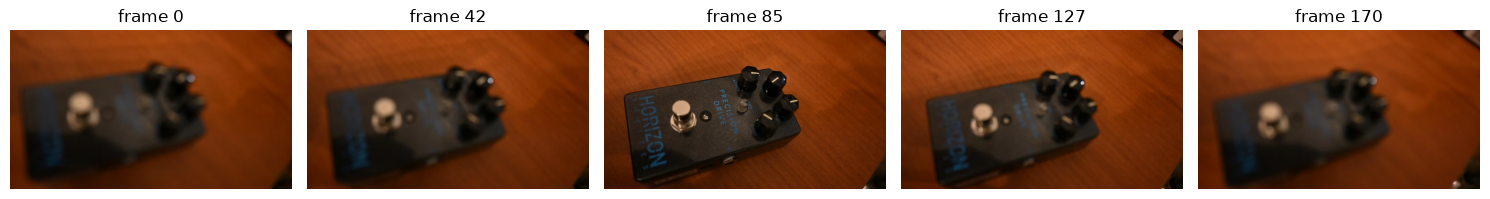

In [ ]:
plot_frames(frames, N_FRAMES)

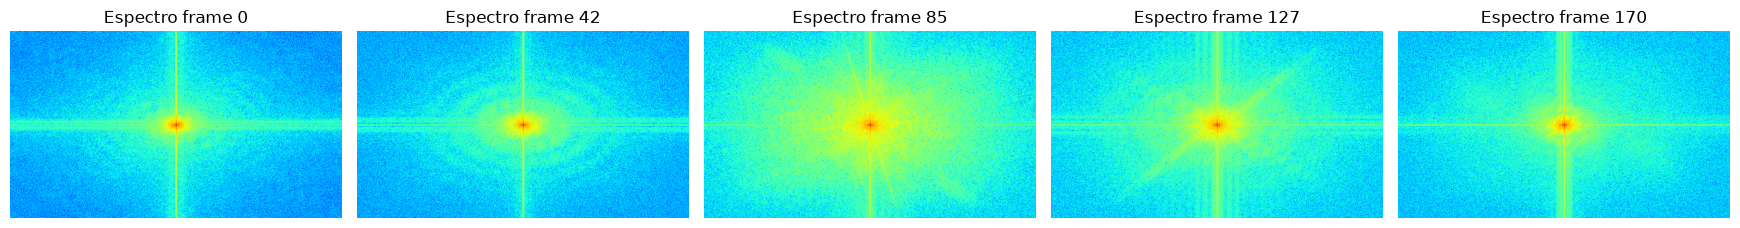

In [28]:
plot_espectros(frames, N_FRAMES)

La FFT descompone cada frame en ondas de distinta frecuencia: el centro del espectro es la frecuencia cero y, cuanto más alajado del centro, más rápido es el cambio de brillo que representa. Los bordes son cambios abruptos y requieren altas frecuencias, por lo que una imagen nítida tiene energía lejos del centro. Desenfocar equivale a promediar cada píxel con sus vecinos, lo que elimina los cambios rápidos (filtro pasa-bajos). Esto se observa en los plots: en los frames 0 y 170 el pedal está desenfocado y la mayor parte de la energía queda concentrada en el centro, mientras que en el frame 85, el más nítido, el espectro se expande hacia la periferia.

La métrica del paper cuantifica esa extensión: cuenta qué proporción de las frecuencias supera un umbral relativo al máximo, y a mayor proporción, mayor nitidez. Esperaríamos entonces encontrar un máximo cerca del frame 85 y mínimos en los extremos.

### Algoritmo que calcula métrica de Nitidez en Frecuencia (Paper)

El paper ["Image Sharpness Measure for Blurred Images in Frequency Domain" (De y Masilamani, 2013)](./data/tp2/ImageSharpnessMeasureforBlurredImagesinFrequency.pdf) propone una medida de nitidez sin referencia, llamada **FM** (*Frequency Domain Image Blur Measure*), basada en el espectro de Fourier. Su observación central es que, al aumentar el desenfoque, disminuye la cantidad de componentes de alta frecuencia.

Dada una imagen $I$ de tamaño $M \times N$, el paper propone el siguiente algoritmo:

1. Calcular la transformada de Fourier $F$ de la imagen $I$.
2. Hallar $F_c$, que se obtiene desplazando el origen de $F$ al centro.
3. Calcular la magnitud: $AF = \text{abs}(F_c)$, donde $AF$ es el valor absoluto de la transformada de Fourier centrada $F_c$ de la imagen $I$.
4. Calcular $AF_{\max} = \max(AF)$, donde $AF_{\max}$ es el valor máximo de las componentes de frecuencia de $F$. (Aclaración: es el valor que el paper denota $M$; lo renombramos para no confundirlo con el tamaño $M \times N$ de la imagen.)
5. Definir el umbral $\text{thres} = \dfrac{AF_{\max}}{1000}$ y contar los píxeles del espectro que lo superan:

$$T_H = \#\{(u,v) \;:\; AF(u,v) > \text{thres}\}$$

6. Calcular la medida de calidad de imagen (FM):

$$\text{Medida de calidad de imagen (FM)} = \frac{T_H}{M \times N} \tag{1}$$

Un valor de $FM$ mayor indica una imagen más nítida, ya que una mayor fracción de las frecuencias supera el umbral. El umbral $1/1000$ se fijó experimentalmente sobre el Berkeley Segmentation Dataset. Los autores muestran que $FM$ decrece de forma monótona al aumentar el desenfoque gaussiano o de movimiento.

In [29]:
def FM(img_rgb: np.ndarray, ratio: float = 1000) -> float:
    """Métrica FM del paper sobre una imagen o región RGB."""

    af = calcular_espectro(img_rgb)        # pasos 1-3: FFT, centrado y |Fc| --> ya estaba implementado en los helpers
    af_max = af.max()                      # paso 4
    thres = af_max / ratio                 # umbral = AF_max / 1000
    t_h = np.count_nonzero(af > thres)     # paso 5: píxeles que superan el umbral
    m, n = af.shape
    return t_h / (m * n)                   # paso 6: FM = T_H / (M x N)

### Experimento 1: curva sobre el frame completo

Lo corremos sobre todos los frames y graficamos el resultado.

In [44]:
fm_completo = [FM(f) for f in frames]

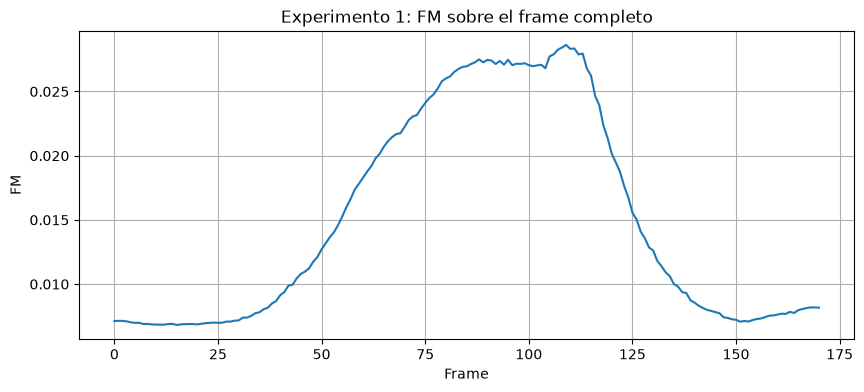

In [45]:
plt.figure(figsize=(10, 4))
plt.plot(fm_completo)
plt.xlabel('Frame')
plt.ylabel('FM')
plt.title('Experimento 1: FM sobre el frame completo')
plt.grid(True)
plt.show()

### Experimento 2: ROI central